# Experiment 5: reflection, redraw and invariant functions

This notebook compares two augmentations with identical prices for every linear latent quantity but different nonlinear invariants. The reflection/redraw comparison supplies Experiment 5 of the report. A separate output-head comparison is retained as an exploratory experiment.

All ten latent coordinates are independent standard Gaussian variables. The five content factors are copied exactly. Each default condition uses six encoder outputs, temperature $\tau=0.1$, and seeds 0, 1 and 2.

| Comparison | Conditions | Changed component | Role |
| --- | --- | --- | --- |
| Output head | `unbounded_d6`, `box_d6` | Identity or sigmoid output head, with additive style perturbations | Exploratory |
| Augmentation | `flip_d6`, `redraw_d6` | Random reflection or independent redraw of $s_1$, with an identity head | Report Experiment 5 |

The saved outputs contain all 12 condition/seed trajectories, evaluated at 10,000, 30,000 and 60,000 updates: 36 checkpoint evaluations. Each trajectory continues through these budgets. The optional sphere and five-output conditions are disabled.

Part A defines the shared simulation components; Part B defines the comparisons and evaluation. Saved tables and figures can be read without execution. To rerun, execute the cells in order and retain `NL_DIR` in persistent storage. Compatible checkpoints support continuation; the external checkpoint and result directories are not bundled with the notebook.


## Part A: shared simulation setup

These cells define the Gaussian reference model, latent augmentation, fixed mixing network, encoder, and contrastive loss. The implementation is adapted from the synthetic experiments in [von Kügelgen et al. (2021)](https://arxiv.org/abs/2106.04619) and their [released code](https://github.com/ysharma1126/ssl_identifiability/tree/ee46a35acf68461172b3eaeeb1d6fbc779fce661). Part B specifies the distributions, augmentation rules, output dimensions, and training budgets used in this notebook.

The notebook is self-contained. Run the setup before executing Part B; the saved tables and figures can be read without rerunning training.


### Environment and settings

The code uses Python, PyTorch, NumPy, SciPy, pandas, Matplotlib, and scikit-learn. The next cell records the software versions used for the saved execution. Dependencies are listed in the repository's `requirements.txt`. The device setting selects CUDA, then Apple MPS, then CPU when available; rerun results can vary across devices and software versions.


In [1]:
import copy
import math
import platform
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import wishart
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

import torch
from torch import nn
from IPython.display import display

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelsize": 11, "axes.titlesize": 12, "font.size": 10,
})

versions = {
    "Python": platform.python_version(), "PyTorch": torch.__version__,
    "NumPy": np.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
display(pd.Series(versions, name="Version").to_frame())

,Version
Python,3.13.15
PyTorch,2.11.0+cu130
NumPy,2.1.3
SciPy,1.16.3
scikit-learn,1.6.1


### Reference scenarios

The four scenarios follow the synthetic comparisons in Section 5.1 of [von Kügelgen et al. (2021)](https://arxiv.org/abs/2106.04619).

| Scenario | Style-coordinate selection probability | Dependence within blocks | Style depends on content |
| --- | ---: | --- | --- |
| `independent_all` | 1.00 | No | No |
| `independent_partial` | 0.75 | No | No |
| `dependent_blocks` | 0.75 | Yes | No |
| `content_causes_style` | 0.75 | Yes | Yes |

The reference model has five content factors and five style factors. `representation_dim` sets the number of encoder outputs, independently of those latent dimensions. Each update uses fresh simulated data; `batch_size` sets both the number of positive pairs and the size of the independent negative pool. The experiment cells below override the reference settings as needed.


In [2]:
# CHANGED v3: the shared defaults agree with the independent Gaussian comparison.
SCENARIO = "independent_all"

SCENARIOS = {
    "independent_all":      (1.00, False, False),
    "independent_partial":  (0.75, False, False),
    "dependent_blocks":     (0.75, True,  False),
    "content_causes_style": (0.75, True,  True),
}

@dataclass
class Settings:
    seed: int = 7                          # Controls randomness so a run can be repeated.
    content_dim: int = 5                   # Number of true content variables, unchanged across paired views.
    style_dim: int = 5                     # Number of true style variables, which may change across views.
    representation_dim: int = 5            # Number of encoder outputs; equals content_dim.
    style_change_prob: float = 0.75        # Probability that each style coordinate is selected for change ("Biased Coin")
    statistical_dependence: bool = False   # If True, allow correlations within content, style noise, and augmentation noise.
    content_dependent_style: bool = False  # If True, generate style as s = a + Bc + noise.
    marginal_std: float = 1.0              # Standard deviation of content and residual style noise when dependence is off.
    style_noise_std: float = 1.0           # Standard deviation of noise added to selected style coordinates when dependence is off.
    mixing_layers: int = 3                 # Number of linear layers in the fixed latent-to-observation network.
    condition_pool: int = 25000            # Number of random matrices used to estimate a conditioning threshold.
    condition_quantile: float = 0.001      # Set the threshold using roughly the best-conditioned 0.1% of those matrices.
    learning_rate: float = 1e-4            # Controls the size of the encoder's parameter updates during training.
    temperature: float = 1.0               # Scales distances in the contrastive loss; smaller values sharpen comparisons.
    batch_size: int = 1024                  # Positive pairs per update; also the number of independent negative examples.
    steps: int = 10000                      # Total number of encoder parameter updates.
    log_every: int = 200                   # Print training progress every this many updates.
    probe_train_size: int = 3000            # Examples used to fit evaluation models that predict latents from representations.
    probe_test_size: int = 5000            # Separate examples used to test those evaluation models.
    device: str = "auto"                   # Automatically choose CUDA, then MPS, then CPU; can also set one explicitly.

cfg = Settings()
(cfg.style_change_prob, cfg.statistical_dependence,
 cfg.content_dependent_style) = SCENARIOS[SCENARIO]

# Original script's training scale (not enabled for this demonstration):
# cfg.batch_size = 6144
# cfg.steps = 100001
# The original nonlinear evaluation fits probes on 5 * 4096 examples and
# evaluates on 10 fresh batches of 4096. Kernel regression at that size is costly.

assert min(cfg.content_dim, cfg.style_dim, cfg.representation_dim) >= 1
assert 0 <= cfg.style_change_prob <= 1
assert min(cfg.marginal_std, cfg.style_noise_std, cfg.temperature) > 0
assert cfg.steps > 0 and cfg.batch_size > 1

if cfg.device != "auto":
    device = torch.device(cfg.device)
elif torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

torch.manual_seed(cfg.seed)
torch.set_num_threads(2)  # Avoid oversubscribing CPU cores in small examples.
latent_dim = cfg.content_dim + cfg.style_dim
print(f"Scenario: {SCENARIO}; device: {device}")
display(pd.Series(asdict(cfg), name="Setting").to_frame())


Scenario: independent_all; device: cuda


,Setting
seed,7
content_dim,5
style_dim,5
representation_dim,5
style_change_prob,1.0
statistical_dependence,False
content_dependent_style,False
marginal_std,1.0
style_noise_std,1.0
mixing_layers,3


### Gaussian reference model

The reference sampler draws

$$
c\sim N(0,\Sigma_c),\qquad
s=a+Bc+\varepsilon_s,\qquad
\varepsilon_s\sim N(0,\Sigma_s),
$$

with independent draws of $c$ and $\varepsilon_s$. In the independent scenarios, the covariance matrices are scalar multiples of the identity. In the dependent scenarios, Wishart draws provide positive definite covariance matrices and replace the scalar variance settings. Setting `content_dependent_style=True` introduces the term $a+Bc$; otherwise $a=B=0$.

The world parameters are fixed within a run. Repeated samples therefore come from the same data-generating distribution. Experiment-specific samplers are defined in Part B.


In [3]:
def make_world(settings):
    """Create fixed parameters of the data distribution on the CPU."""
    rng = np.random.default_rng(settings.seed)
    nc, ns = settings.content_dim, settings.style_dim

    def covariance(dim, std):
        if settings.statistical_dependence:
            # Match the intended Wishart construction in the original experiment.
            matrix = np.atleast_2d(wishart.rvs(df=dim, scale=np.eye(dim), random_state=rng))
        else:
            matrix = (std ** 2) * np.eye(dim)
        return torch.tensor(matrix, dtype=torch.float64)

    Sigma_c = covariance(nc, settings.marginal_std)
    Sigma_s = covariance(ns, settings.marginal_std)
    Sigma_aug = covariance(ns, settings.style_noise_std)
    # As in upstream spaces.py, explicit covariances supersede the std arguments.
    a = torch.zeros(ns)
    B = torch.zeros(ns, nc)
    if settings.content_dependent_style:
        a = torch.tensor(rng.standard_normal(ns), dtype=torch.float32)
        B = torch.tensor(rng.standard_normal((ns, nc)), dtype=torch.float32)
    return {
        "L_c": torch.linalg.cholesky(Sigma_c).float(),
        "L_s": torch.linalg.cholesky(Sigma_s).float(),
        "L_aug": torch.linalg.cholesky(Sigma_aug).float(),
        "a": a, "B": B,
    }

world = make_world(cfg)

def sample_latents(size, generator):
    """Draw z=(c,s). Latent values are used by the simulator and evaluator."""
    c = torch.randn(size, cfg.content_dim, generator=generator) @ world["L_c"].T
    eps_s = torch.randn(size, cfg.style_dim, generator=generator) @ world["L_s"].T
    s = world["a"] + c @ world["B"].T + eps_s
    return torch.cat([c, s], dim=1)

display(pd.DataFrame({
    "block": ["content", "style residual", "augmentation noise"],
    "dimension": [cfg.content_dim, cfg.style_dim, cfg.style_dim],
    "covariance": ["L_c @ L_c.T", "L_s @ L_s.T", "L_aug @ L_aug.T"],
}))

,block,dimension,covariance
0,content,5,L_c @ L_c.T
1,style residual,5,L_s @ L_s.T
2,augmentation noise,5,L_aug @ L_aug.T


### Reference augmentation and negative samples

The reference augmentation copies content and adds masked Gaussian noise to style:

$$
M_j\sim\operatorname{Bernoulli}(p),\qquad
\tilde s=s+M\odot\eta,\qquad
\eta\sim N(0,\Sigma_{\mathrm{aug}}).
$$

The mask entries are independent, and the mask and noise are independent of the original latents. The operator $\odot$ denotes coordinatewise multiplication. When $p>0$ and $\Sigma_{\mathrm{aug}}$ is positive definite, every style coordinate can vary locally. The negative samples are independent draws from the original latent distribution. Part B defines any changes to this reference augmentation.


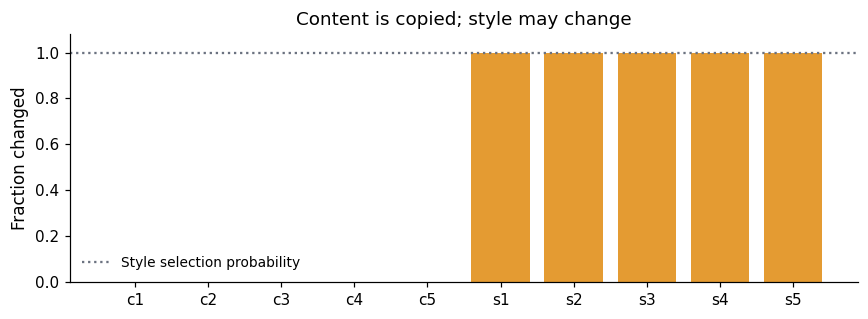

In [4]:
def augment_latents(z, generator):
    nc = cfg.content_dim
    style = z[:, nc:]
    mask = (torch.rand(style.shape, generator=generator) < cfg.style_change_prob)
    noise = torch.randn(style.shape, generator=generator) @ world["L_aug"].T
    changed_style = style + mask * noise
    return torch.cat([z[:, :nc], changed_style], dim=1)

def sample_triplet(size, generator):
    z = sample_latents(size, generator)
    z_negative = sample_latents(size, generator)
    z_augmented = augment_latents(z, generator)
    return z, z_augmented, z_negative

# A separate random stream keeps this inspection from changing training data.
inspection_rng = torch.Generator().manual_seed(cfg.seed + 10)
z_check, z_aug_check, _ = sample_triplet(5000, inspection_rng)
assert torch.equal(z_check[:, :cfg.content_dim], z_aug_check[:, :cfg.content_dim])
change_rates = (z_check != z_aug_check).float().mean(dim=0).numpy()
names = ([f"c{i+1}" for i in range(cfg.content_dim)] +
         [f"s{i+1}" for i in range(cfg.style_dim)])

fig, ax = plt.subplots(figsize=(8, 3))
colors = ["#227c9d"] * cfg.content_dim + ["#e49b32"] * cfg.style_dim
ax.bar(names, change_rates, color=colors)
ax.axhline(cfg.style_change_prob, color="#6b7280", linestyle=":", label="Style selection probability")
ax.set(ylim=(0, 1.08), ylabel="Fraction changed", title="Content is copied; style may change")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### Fixed mixing network

The mixing network maps $z=(c,s)$ to $x=f(z)$. Its square nonsingular weight matrices and LeakyReLU activations with nonzero negative slope make the map invertible. The code selects well-conditioned matrices to limit numerical distortion, then freezes the mixing network during encoder training.

LeakyReLU has a kink at zero, so this implementation is not smooth everywhere as required by the paper's theoretical model.


In [5]:
def make_mixing(settings):
    """Adapt the upstream well-conditioned, square mixing MLP."""
    n = settings.content_dim + settings.style_dim
    rng = np.random.default_rng(settings.seed + 100)

    def candidate():
        matrix = rng.uniform(-1, 1, size=(n, n))
        return matrix / np.linalg.norm(matrix, axis=0, keepdims=True)

    conditions = np.array([
        np.linalg.cond(candidate()) for _ in range(settings.condition_pool)
    ])
    threshold = np.sort(conditions)[int(settings.condition_pool * settings.condition_quantile)]
    modules, accepted_conditions = [], []
    for layer in range(settings.mixing_layers):
        matrix = candidate()
        while np.linalg.cond(matrix) > threshold:
            matrix = candidate()
        linear = nn.Linear(n, n, bias=False)
        with torch.no_grad():
            linear.weight.copy_(torch.tensor(matrix, dtype=torch.float32))
        modules.append(linear)
        accepted_conditions.append(np.linalg.cond(matrix))
        if layer < settings.mixing_layers - 1:
            modules.append(nn.LeakyReLU(negative_slope=0.2))
    network = nn.Sequential(*modules).to(device)
    network.requires_grad_(False)
    network.eval()
    return network, accepted_conditions

mixing, condition_numbers = make_mixing(cfg)
print("Mixing layer condition numbers:", np.round(condition_numbers, 2))
print("Mixing parameters trainable:", any(p.requires_grad for p in mixing.parameters()))

with torch.no_grad():
    x_check = mixing(z_check[:5].to(device))
print("Latent shape:", tuple(z_check[:5].shape))
print("Observation shape:", tuple(x_check.shape))

Mixing layer condition numbers: [4.56 4.26 4.91]
Mixing parameters trainable: False
Latent shape: (5, 10)
Observation shape: (5, 10)


### Encoder

The base encoder uses the hidden-layer widths and LeakyReLU activations of the released `main_mlp.py`, with an unbounded final linear layer. Its output dimension is $d=\texttt{representation_dim}$. The learned composite map is $h=g\circ f$, from the ten latent coordinates to $d$ representation coordinates. Part B specifies the output dimension and any additional output transformation.


In [6]:
def make_encoder(settings):
    n = settings.content_dim + settings.style_dim
    # Same hidden widths as main_mlp.py; final layer has no activation.
    widths = [n, n * 10, n * 50, n * 50, n * 50, n * 50, n * 10,
              settings.representation_dim]
    modules = []
    for i, (n_in, n_out) in enumerate(zip(widths[:-1], widths[1:])):
        modules.append(nn.Linear(n_in, n_out))
        if i < len(widths) - 2:
            modules.append(nn.LeakyReLU(negative_slope=0.01))
    return nn.Sequential(*modules).to(device)

torch.manual_seed(cfg.seed + 200)
encoder = make_encoder(cfg)
initial_encoder = copy.deepcopy(encoder).eval()
print(encoder)
print("Trainable encoder parameters:", sum(p.numel() for p in encoder.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=100, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=100, out_features=500, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=500, out_features=500, bias=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=500, out_features=500, bias=True)
  (7): LeakyReLU(negative_slope=0.01)
  (8): Linear(in_features=500, out_features=500, bias=True)
  (9): LeakyReLU(negative_slope=0.01)
  (10): Linear(in_features=500, out_features=100, bias=True)
  (11): LeakyReLU(negative_slope=0.01)
  (12): Linear(in_features=100, out_features=5, bias=True)
)
Trainable encoder parameters: 853705


### Contrastive objective

Let $u_i=g(x_i)$, $v_i=g(\tilde x_i)$, and $w_j=g(x_j^-)$. The first two form a positive pair; $w_j$ comes from the independent negative pool. Define

$$
d_i^+=\|u_i-v_i\|_2^2,\qquad d_{ij}^-=\|u_i-w_j\|_2^2.
$$

For batch size $m$ and temperature $\tau$, the implemented loss is

$$
\frac1m\sum_{i=1}^m\left[
\frac{d_i^+}{\tau}
+\log\left(\frac{e^{-d_i^+/\tau}+\sum_{j=1}^m e^{-d_{ij}^-/\tau}}{m+1}\right)
\right].
$$

This matches the released implementation's squared-distance objective at $p=2$ and $\alpha=0.5$. Dividing by $m+1$ inside the logarithm shifts the usual summed-denominator loss by a constant; negative loss values are therefore expected. The loss encourages agreement within positive pairs relative to independent negatives.

This finite-batch contrastive objective does not compute differential entropy directly. It differs from the population alignment–entropy objective on a bounded output domain in Theorem 4.4; the experiments assess finite-training behavior.


In [7]:
def contrastive_loss(anchor, positive, negative, temperature=1.0):
    """Same objective as LpSimCLRLoss at its default p=2, alpha=0.5."""
    positive_distance = (anchor - positive).square().sum(dim=1)
    # Algebraically equal to all pairwise squared differences, using less memory.
    negative_distance = (
        anchor.square().sum(dim=1, keepdim=True)
        + negative.square().sum(dim=1).unsqueeze(0)
        - 2 * anchor @ negative.T
    ).clamp_min(0)
    all_distances = torch.cat([negative_distance, positive_distance[:, None]], dim=1)
    alignment = positive_distance / temperature
    contrast = torch.logsumexp(-all_distances / temperature, dim=1)
    contrast = contrast - math.log(all_distances.shape[1])
    loss = (alignment + contrast).mean()
    return loss, alignment.mean().detach(), contrast.mean().detach()

zero = torch.zeros(8, cfg.representation_dim, device=device)
collapsed_loss, _, _ = contrastive_loss(zero, zero, zero, cfg.temperature)
print(f"Loss of a constant representation: {collapsed_loss.item():.3f}")

Loss of a constant representation: 0.000


## Part B: Experiment 5 and the exploratory head comparison


### Conditions and training budgets

`NL_SEEDS` specifies the three replications and `NL_BUDGETS` the evaluation checkpoints. Within a seed, the default conditions share the mixing network, encoder initialization before the output head, and sampling streams. In the additive head comparison, $s_1$ has price $0.09$ and the other styles have price $1$. Reflection and redraw both give $s_1$ price $2$. The optional conditions are excluded from the saved default comparison.


In [8]:
# CHANGED v3 [1]: matched Gaussian conditions, exact content, and shared checkpoints.
import hashlib
import json
import random
import types
from dataclasses import asdict, replace
import sklearn

NL_SEEDS = [0, 1, 2]
NL_BUDGETS = [10000, 30000, 60000]  # One continuous trajectory, not three restarts.
NL_STEPS = max(NL_BUDGETS)
NL_SAVE_EVERY = 5000
NL_WORLD = 'gaussian'
NL_TEMPERATURE = 0.1              # SAME temperature in every matched comparison.
NL_CONTENT_STD = 0.0              # Restores exact content invariance.
NL_S1_STD = 0.30                  # Additive price 0.09; other styles have price 1.
NL_OTHER_STD = 1.00
NL_FLIP_PROB = 0.5
NL_CONTENT_MARGINAL = 'uniform'   # Used only if an optional non-Gaussian world is selected.
NL_PRICE_SAMPLES = 50000
NL_SAVE_ARRAYS = True
NL_INCLUDE_OPTIONAL = False       # Sphere and matched five-output augmentation runs.
NL_DIR = Path('extension_experiment5_gaussian_v3')  # Use a persistent path on Colab.
NL_DIR.mkdir(parents=True, exist_ok=True)
NL_TRAIN_VERSION = 'exp5_gaussian_exact_content_v3'
NL_PROBE_VERSION = 'exp5_separate_function_probes_v3'

NC, NS = cfg.content_dim, cfg.style_dim
N = NC + NS
COORDS = [f'c{i+1}' for i in range(NC)] + [f's{i+1}' for i in range(NS)]
NL_TARGETS = COORDS + ['abs_s1', 'sign_s1']
NL_CONTENT_LABEL = 'content' if NL_CONTENT_STD == 0 else 'original content'
base_nl = replace(cfg, style_change_prob=1.0, statistical_dependence=False,
                  content_dependent_style=False, steps=NL_STEPS)

# CHANGED: scientific parts are explicit; 'unbounded' is a head, not a linear encoder.
NL_CORE_CONDITIONS = [
    dict(label='unbounded_d6', part='heads', world=NL_WORLD, head='unbounded',
         tau=NL_TEMPERATURE, change='additive', rep_dim=NC + 1),
    dict(label='box_d6', part='heads', world=NL_WORLD, head='box',
         tau=NL_TEMPERATURE, change='additive', rep_dim=NC + 1),
    dict(label='flip_d6', part='augmentation', world=NL_WORLD, head='unbounded',
         tau=NL_TEMPERATURE, change='flip', rep_dim=NC + 1),
    dict(label='redraw_d6', part='augmentation', world=NL_WORLD, head='unbounded',
         tau=NL_TEMPERATURE, change='redraw', rep_dim=NC + 1),
]
# OPTIONAL, excluded by default: the sphere changes ambient width and geometry.
# The five-output pair tests competition among invariant quantities, not extra capacity.
NL_OPTIONAL_CONDITIONS = [
    dict(label='sphere_d7', part='heads', world=NL_WORLD, head='sphere',
         tau=NL_TEMPERATURE, change='additive', rep_dim=NC + 2),
    dict(label='flip_d5', part='augmentation', world=NL_WORLD, head='unbounded',
         tau=NL_TEMPERATURE, change='flip', rep_dim=NC),
    dict(label='redraw_d5', part='augmentation', world=NL_WORLD, head='unbounded',
         tau=NL_TEMPERATURE, change='redraw', rep_dim=NC),
]
NL_CONDITIONS = NL_CORE_CONDITIONS + (NL_OPTIONAL_CONDITIONS if NL_INCLUDE_OPTIONAL else [])

assert NC >= 1 and NS >= 2
assert NL_SEEDS and len(set(NL_SEEDS)) == len(NL_SEEDS)
assert all(isinstance(s, int) and s >= 0 for s in NL_SEEDS)
assert NL_BUDGETS == sorted(set(NL_BUDGETS)) and min(NL_BUDGETS) > 0
assert all(isinstance(b, int) for b in NL_BUDGETS)
assert NL_SAVE_EVERY > 0 and NL_PRICE_SAMPLES > 1
assert NL_CONTENT_STD >= 0 and min(NL_S1_STD, NL_OTHER_STD) > 0
assert NL_FLIP_PROB == .5, 'Matched reflection/redraw prices require flip probability 1/2.'
assert NL_CONTENT_MARGINAL in {'uniform', 'laplace'}
assert len({c['label'] for c in NL_CONDITIONS}) == len(NL_CONDITIONS)
assert all(c['head'] in {'unbounded', 'box', 'sphere'} and
           c['change'] in {'additive', 'flip', 'redraw'} and
           c['world'] in {'nongaussian', 'gaussian'} and
           c['tau'] > 0 and 0 < c['rep_dim'] <= N for c in NL_CONDITIONS)
print('Device:', device)
print(f'{len(NL_CONDITIONS)} conditions × {len(NL_SEEDS)} seeds = '
      f'{len(NL_CONDITIONS)*len(NL_SEEDS)} continuous training trajectories.')
print(f'Checkpoints: {NL_BUDGETS}; '
      f'{len(NL_CONDITIONS)*len(NL_SEEDS)*max(NL_BUDGETS):,} fresh updates in total; '
      f'{len(NL_CONDITIONS)*len(NL_SEEDS)*len(NL_BUDGETS)} probe evaluations.')
print('All default conditions share temperature, mixing, pre-head initialization and data streams by seed.')
print('Content is copied exactly.' if NL_CONTENT_STD == 0 else 'Content is perturbed: this changes the default question.')
print('Checkpoints/reports:', NL_DIR.resolve())
print('The earlier non-Gaussian v2 results are kept separate and are not reused as matched controls.')


Device: cuda
4 conditions × 3 seeds = 12 continuous training trajectories.
Checkpoints: [10000, 30000, 60000]; 720,000 fresh updates in total; 36 probe evaluations.
All default conditions share temperature, mixing, pre-head initialization and data streams by seed.
Content is copied exactly.
Checkpoints/reports: /content/extension_experiment5_gaussian_v3
The earlier non-Gaussian v2 results are kept separate and are not reused as matched controls.


### Paired augmentations

Content is copied exactly, and $s_2,\ldots,s_5$ receive independent Gaussian perturbations with standard deviation $1$. Only the rule for $s_1$ differs between the report conditions:

$$
\widetilde s_1=\varepsilon s_1,\qquad
\Pr(\varepsilon=1)=\Pr(\varepsilon=-1)=\tfrac12
\quad\text{(reflection)},
$$

or $\widetilde s_1\sim N(0,1)$ (redraw). The reflection sign, redraw, and Gaussian perturbations of the other style coordinates are mutually independent and independent of the original latents. Both rules preserve the marginal distribution of $s_1$. Auxiliary random variables are drawn in every mode so that originals, negatives and changes to other coordinates remain paired across conditions.


In [9]:
# CHANGED v3 [2]: Gaussian draws, exact content copying, and paired augmentation streams.
def laplace(shape, gen, std):
    """Centered Laplace draws with the requested standard deviation."""
    b = std / np.sqrt(2.)
    e1 = -torch.log1p(-torch.rand(shape, generator=gen))
    e2 = -torch.log1p(-torch.rand(shape, generator=gen))
    return b * (e1 - e2)


def nl_noise(shape, gen, std, world):
    if world == 'gaussian':
        return torch.randn(shape, generator=gen) * std
    if world == 'nongaussian':
        return laplace(shape, gen, std)
    raise ValueError(f'Unknown world: {world}')


def nl_draw_z(size, gen, world):
    if world == 'gaussian':
        return torch.randn(size, N, generator=gen)
    if world != 'nongaussian':
        raise ValueError(f'Unknown world: {world}')
    if NL_CONTENT_MARGINAL == 'laplace':
        c = laplace((size, NC), gen, 1.)
    else:
        c = (torch.rand(size, NC, generator=gen) * 2. - 1.) * np.sqrt(3.)
    s = laplace((size, NS), gen, 1.)
    return torch.cat([c, s], dim=1)


def nl_change_std():
    values = np.full(N, NL_OTHER_STD, dtype=np.float32)
    values[:NC] = NL_CONTENT_STD
    values[NC] = NL_S1_STD
    return torch.as_tensor(values)


def nl_perturb(z, gen, world, change):
    """Only s1 differs across modes; content is copied when NL_CONTENT_STD is zero.

    Draw every auxiliary variable in every mode, including unused ones, so that
    the non-s1 perturbations stay exactly paired across modes on the same backend.
    """
    if change not in {'additive', 'flip', 'redraw'}:
        raise ValueError(f'Unknown change: {change}')
    augmented = z + nl_noise(z.shape, gen, 1., world) * nl_change_std()
    flip_mask = torch.rand(z.shape[0], generator=gen) < NL_FLIP_PROB
    redraw = nl_noise((z.shape[0],), gen, 1., world)  # SAME marginal as original s1
    if change == 'flip':
        sign = torch.where(flip_mask, -1., 1.)
        augmented[:, NC] = z[:, NC] * sign
    elif change == 'redraw':
        augmented[:, NC] = redraw
    return augmented


def nl_seed(seed, offset):
    # Disjoint blocks avoid seed-0's negative stream equalling seed-1's original stream.
    return 10000 * int(seed) + int(offset)


def nl_training_streams(seed):
    return {name: torch.Generator().manual_seed(nl_seed(seed, offset)) for name, offset in
            [('original', 300), ('negative', 301), ('augmentation', 302)]}


def nl_triplet(size, streams, world, change):
    z = nl_draw_z(size, streams['original'], world)
    negative = nl_draw_z(size, streams['negative'], world)
    augmented = nl_perturb(z, streams['augmentation'], world, change)
    return z, augmented, negative


def nl_targets(z):
    s1 = z[:, NC:NC + 1]
    return torch.cat([z, s1.abs(), torch.sign(s1)], dim=1)


def nl_pair_diagnostics(world, change, n=NL_PRICE_SAMPLES):
    z = nl_draw_z(n, torch.Generator().manual_seed(12345), world)
    augmented = nl_perturb(z, torch.Generator().manual_seed(12346), world, change)
    before, after = nl_targets(z).numpy(), nl_targets(augmented).numpy()
    delta = after.astype(np.float64) - before.astype(np.float64)
    variance = before.astype(np.float64).var(axis=0, ddof=1)
    rows = []
    for j, target in enumerate(NL_TARGETS):
        rows.append(dict(world=world, change=change, target=target,
                         price_variance=float(delta[:, j].var(ddof=1) / variance[j]),
                         relative_pair_mse=float(np.mean(delta[:, j] ** 2) / variance[j]),
                         mean_change=float(delta[:, j].mean())))
    return pd.DataFrame(rows)


class Head(nn.Module):
    """Output geometry: unbounded, sigmoid box, or unit-normalised sphere."""
    def __init__(self, kind):
        super().__init__()
        if kind not in {'unbounded', 'box', 'sphere'}:
            raise ValueError(kind)
        self.kind = kind

    def forward(self, u):
        if self.kind == 'box':
            return torch.sigmoid(u)
        if self.kind == 'sphere':
            return nn.functional.normalize(u, dim=1, eps=1e-12)
        return u


### Recovery probes and forward fits

Recovery probes predict latent coordinates, $|s_1|$ and $\operatorname{sign}(s_1)$ from the representation. Kernel hyperparameters are selected separately for magnitude and sign, and jointly within each latent block. Forward fits predict representations from latents, using separate fitting and evaluation halves of the test sample. Their absolute linear $R^2$ and kernel-minus-linear gap measure approximation over this sample. Nearly constant output coordinates are excluded from the forward averages and counted explicitly.


In [10]:
# CHANGED v3 [3]: fit each derived target separately; flag constant forward outputs.
# Recovery and forward fits are different prediction directions.
KRR_GRID = {'kernelridge__alpha': [1., .1, .01, .001],
            'kernelridge__gamma': [float(g) for g in np.logspace(-2, 2, 4)]}


def kernel_fit(X_tr, Y_tr):
    search = GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel='rbf')),
                          KRR_GRID, scoring='r2', cv=3, n_jobs=1)
    with threadpool_limits(limits=2):
        search.fit(X_tr, Y_tr)
    return search


def nl_probe(X_tr, Y_tr, X_te, Y_te):
    linear = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, Y_tr)
    pred_linear = linear.predict(X_te)
    pred_kernel = np.zeros_like(Y_te)
    # Independent selection for magnitude and sign avoids a joint search compromising
    # the invariant-magnitude question. Content/style blocks keep the shared protocol.
    for cols in (slice(0, NC), slice(NC, N), slice(N, N + 1), slice(N + 1, N + 2)):
        pred_kernel[:, cols] = kernel_fit(X_tr, Y_tr[:, cols]).predict(X_te)
    return (r2_score(Y_te, pred_linear, multioutput='raw_values'),
            r2_score(Y_te, pred_kernel, multioutput='raw_values'),
            pred_linear, pred_kernel)


def linearity_of_h(X, Z):
    """Forward held-out fits: Z predicts X. Read absolute linear R² and its gap."""
    n = len(Z) // 2
    linear = make_pipeline(StandardScaler(), LinearRegression()).fit(Z[:n], X[:n])
    lin_r2 = r2_score(X[n:], linear.predict(Z[n:]), multioutput='raw_values')
    ker_r2 = r2_score(X[n:], kernel_fit(Z[:n], X[:n]).predict(Z[n:]), multioutput='raw_values')
    # R² of a constant forward target is not evidence of a successful linear map.
    constant = X[n:].var(axis=0) <= 1e-12
    lin_r2[constant] = np.nan
    ker_r2[constant] = np.nan
    return lin_r2, ker_r2


def nl_finite_mean(values):
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]
    return float(finite.mean()) if len(finite) else None


### Cache identities and saved state

Training caches identify the numerical design, relevant code and runtime. The final training horizon is excluded, allowing a compatible trajectory to continue when `NL_BUDGETS` is extended. Evaluation caches have a separate identity. Checkpoints and results are stored under `extension_experiment5_gaussian_v3`; they require the external files, not just the outputs embedded in this notebook.


In [11]:
# RETAINED v3: code-aware cache identities and full training-state checkpoints.
def nl_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(',', ':'),
                                     allow_nan=False).encode()).hexdigest()[:16]


def nl_code_signature(value):
    """Ignore cell filenames/line numbers, which change between notebook sessions."""
    if hasattr(value, '__code__'):
        value = value.__code__
    if isinstance(value, types.CodeType):
        return dict(bytecode=value.co_code.hex(), names=list(value.co_names),
                    varnames=list(value.co_varnames), freevars=list(value.co_freevars),
                    cellvars=list(value.co_cellvars), argcount=value.co_argcount,
                    kwonlyargcount=value.co_kwonlyargcount,
                    constants=[nl_code_signature(item) for item in value.co_consts])
    if isinstance(value, bytes):
        return {'bytes': value.hex()}
    if isinstance(value, (tuple, list)):
        return [nl_code_signature(item) for item in value]
    if isinstance(value, frozenset):
        return {'frozenset': sorted([nl_code_signature(item) for item in value], key=repr)}
    if value is None or isinstance(value, (str, int, float, bool)):
        return value
    return {'type': type(value).__name__, 'repr': repr(value)}


def nl_training_configuration(settings, condition):
    values = asdict(settings)
    for key in ['steps', 'probe_train_size', 'probe_test_size', 'log_every', 'device']:
        values.pop(key, None)
    functions = [laplace, nl_noise, nl_draw_z, nl_change_std, nl_perturb,
                 nl_seed, nl_training_streams, nl_triplet, Head.__init__, Head.forward, make_mixing,
                 make_encoder, contrastive_loss, nl_train_to_budgets]
    return dict(version=NL_TRAIN_VERSION, settings=values,
                world=condition['world'], head=condition['head'], change=condition['change'],
                original_content_marginal=(NL_CONTENT_MARGINAL if condition['world'] == 'nongaussian' else 'gaussian'),
                content_std=float(NL_CONTENT_STD), other_std=float(NL_OTHER_STD),
                additive_s1_std=(float(NL_S1_STD) if condition['change'] == 'additive' else None),
                flip_probability=(float(NL_FLIP_PROB) if condition['change'] == 'flip' else None),
                paired_stream_seeds={name: nl_seed(settings.seed, offset) for name, offset in
                                     [('original', 300), ('negative', 301), ('augmentation', 302)]},
                encoder_seed=nl_seed(settings.seed, 200), mixing_seed=settings.seed + 100,
                runtime_device=str(device), torch_version=str(torch.__version__),
                numpy_version=str(np.__version__),
                numerical_code=nl_digest([nl_code_signature(f) for f in functions]))


def nl_evaluation_configuration(settings):
    return dict(version=NL_PROBE_VERSION, train_size=settings.probe_train_size,
                test_size=settings.probe_test_size, grid=KRR_GRID,
                train_seed=nl_seed(settings.seed, 400), test_seed=nl_seed(settings.seed, 500),
                forward_split='half_test_for_fit_half_for_score', save_arrays=bool(NL_SAVE_ARRAYS),
                targets=list(NL_TARGETS), sklearn_version=str(sklearn.__version__),
                numerical_code=nl_digest([nl_code_signature(f) for f in
                                          [nl_targets, kernel_fit, nl_probe, linearity_of_h, nl_finite_mean,
                                           nl_evaluate]]))


def nl_atomic_json(path, value):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)


def nl_cpu_state(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {key: nl_cpu_state(item) for key, item in value.items()}
    if isinstance(value, list):
        return [nl_cpu_state(item) for item in value]
    if isinstance(value, tuple):
        return tuple(nl_cpu_state(item) for item in value)
    return value


def nl_save_checkpoint(path, net, mix, optimizer, streams, step, config, history):
    state = dict(configuration=config, step=int(step),
                 encoder_state=nl_cpu_state(net.state_dict()),
                 mixing_state=nl_cpu_state(mix.state_dict()),
                 optimizer_state=nl_cpu_state(optimizer.state_dict()),
                 training_stream_states={name: gen.get_state().clone() for name, gen in streams.items()},
                 torch_cpu_rng_state=torch.get_rng_state().clone(),
                 torch_cuda_rng_state=(torch.cuda.get_rng_state(device).cpu()
                                       if device.type == 'cuda' else None),
                 numpy_rng_state=np.random.get_state(), python_rng_state=random.getstate(),
                 history=list(history))
    temporary = path.with_name(path.name + '.tmp')
    torch.save(state, temporary)
    temporary.replace(path)


def nl_load_checkpoint(path, net, mix, optimizer, streams, config):
    # Load only checkpoints produced by this notebook and kept in your own results folder.
    state = torch.load(path, map_location='cpu', weights_only=False)
    if state.get('configuration') != config:
        raise RuntimeError(f'Checkpoint configuration mismatch: {path}')
    net.load_state_dict(state['encoder_state'])
    mix.load_state_dict(state['mixing_state'])
    optimizer.load_state_dict(state['optimizer_state'])
    for param_state in optimizer.state.values():
        for key, value in param_state.items():
            if torch.is_tensor(value) and key != 'step':
                param_state[key] = value.to(device)
    for name, gen in streams.items():
        gen.set_state(state['training_stream_states'][name].cpu())
    torch.set_rng_state(state['torch_cpu_rng_state'].cpu())
    if device.type == 'cuda' and state.get('torch_cuda_rng_state') is not None:
        torch.cuda.set_rng_state(state['torch_cuda_rng_state'].cpu(), device=device)
    np.random.set_state(state['numpy_rng_state'])
    random.setstate(state['python_rng_state'])
    return int(state['step']), list(state.get('history', []))


def nl_checkpoint_before(folder, target):
    candidates = []
    for path in folder.glob('checkpoint_step_*.pt'):
        try:
            step = int(path.stem.rsplit('_', 1)[1])
        except ValueError:
            continue
        if step <= target:
            candidates.append((step, path))
    latest = folder / 'checkpoint_latest.pt'
    if latest.exists():
        step = int(torch.load(latest, map_location='cpu', weights_only=False)['step'])
        if step <= target:
            candidates.append((step, latest))
    return max(candidates, key=lambda item: item[0])[1] if candidates else None


### Checkpoint evaluation

Each checkpoint uses the same held-out latent samples within a seed. Evaluation records coordinate and function recovery, forward-fit scores, output standard deviations, and the minimum representation-covariance eigenvalue. For the sigmoid head, the saturation statistic is the fraction of outputs below $0.05$ or above $0.95$; it describes output scale rather than the cause of a recovery difference.


In [12]:
# CHANGED v3 [4]: report each requested budget, separate function probes, output-scale diagnostics.
def nl_evaluate(net, mix, settings, condition, budget, folder, training_config):
    config = nl_evaluation_configuration(settings)
    identity = nl_digest(config)
    path = folder / f'evaluation_step_{budget}_{identity}.json'
    arrays_path = folder / f'evaluation_step_{budget}_{identity}.npz'
    if path.exists() and (not NL_SAVE_ARRAYS or arrays_path.exists()):
        cached = json.loads(path.read_text())
        if (cached.get('_training_configuration') != training_config or
                cached.get('_evaluation_configuration') != config or
                cached.get('updates') != budget):
            raise RuntimeError(f'Evaluation cache mismatch: {path}')
        print(f'Verified evaluation: {condition["label"]}, seed={settings.seed}, updates={budget:,}.')
        return cached
    net.eval()
    start = time.perf_counter()

    @torch.no_grad()
    def encode(z):
        return torch.cat([net(mix(chunk.to(device))).cpu()
                          for chunk in z.split(512)]).numpy().astype(np.float64)

    z_tr = nl_draw_z(settings.probe_train_size,
                     torch.Generator().manual_seed(nl_seed(settings.seed, 400)), condition['world'])
    z_te = nl_draw_z(settings.probe_test_size,
                     torch.Generator().manual_seed(nl_seed(settings.seed, 500)), condition['world'])
    X_tr, X_te = encode(z_tr), encode(z_te)
    Z_tr, Z_te = z_tr.numpy().astype(np.float64), z_te.numpy().astype(np.float64)
    Y_tr, Y_te = nl_targets(z_tr).numpy().astype(np.float64), nl_targets(z_te).numpy().astype(np.float64)
    # Retain expensive encoded data even if probing is interrupted.
    if NL_SAVE_ARRAYS:
        temporary = arrays_path.with_name(arrays_path.name + '.tmp')
        with temporary.open('wb') as handle:
            np.savez_compressed(handle, X_train=X_tr, X_test=X_te, Z_train=Z_tr,
                                Z_test=Z_te, Y_train=Y_tr, Y_test=Y_te)
        temporary.replace(arrays_path)
    linear, kernel, pred_linear, pred_kernel = nl_probe(X_tr, Y_tr, X_te, Y_te)
    h_linear, h_kernel = linearity_of_h(X_te, Z_te)
    mean_h_linear, mean_h_kernel = nl_finite_mean(h_linear), nl_finite_mean(h_kernel)
    output_std = X_te.std(axis=0)
    if NL_SAVE_ARRAYS:
        temporary = arrays_path.with_name(arrays_path.name + '.tmp')
        with temporary.open('wb') as handle:
            np.savez_compressed(handle, X_train=X_tr, X_test=X_te, Z_train=Z_tr,
                                Z_test=Z_te, Y_train=Y_tr, Y_test=Y_te,
                                pred_linear=pred_linear, pred_kernel=pred_kernel)
        temporary.replace(arrays_path)
    result = dict(condition=condition['label'], part=condition['part'],
                  world=condition['world'], head=condition['head'],
                  change=condition['change'], tau=settings.temperature,
                  rep_dim=settings.representation_dim, seed=settings.seed,
                  updates=int(budget), steps=int(budget),
                  content_mean=float(kernel[:NC].mean()), s1=float(kernel[NC]),
                  others_mean=float(kernel[NC + 1:N].mean()),
                  abs_s1=float(kernel[N]), sign_s1=float(kernel[N + 1]),
                  linear_abs_s1=float(linear[N]),
                  h_linear_r2=mean_h_linear, h_kernel_r2=mean_h_kernel,
                  h_gap=(mean_h_kernel - mean_h_linear
                         if mean_h_kernel is not None and mean_h_linear is not None else None),
                  forward_valid_outputs=int(np.isfinite(h_linear).sum()),
                  s1_probe_gap=float(kernel[NC] - linear[NC]),
                  sat_frac=(float(((X_te < .05) | (X_te > .95)).mean())
                            if condition['head'] == 'box' else None),
                  rep_std=float(output_std.mean()), rep_std_min=float(output_std.min()),
                  rep_std_max=float(output_std.max()),
                  rep_cov_min_eigenvalue=float(np.linalg.eigvalsh(np.cov(X_te, rowvar=False)).min()),
                  output_std=[float(v) for v in output_std],
                  price_content_nominal=float(NL_CONTENT_STD ** 2),
                  price_s1_nominal=float(NL_S1_STD ** 2 if condition['change'] == 'additive' else 2.),
                  price_other_style_nominal=float(NL_OTHER_STD ** 2),
                  evaluation_seconds=time.perf_counter() - start,
                  checkpoint=str(folder / f'checkpoint_step_{budget}.pt'),
                  encoded_arrays=str(arrays_path) if NL_SAVE_ARRAYS else None,
                  _training_configuration=training_config, _evaluation_configuration=config)
    result.update({f'nonlin_{name}': float(value) for name, value in zip(NL_TARGETS, kernel)})
    result.update({f'lin_{name}': float(value) for name, value in zip(NL_TARGETS, linear)})
    result.update({f'h_lin_out{i+1}': float(v) if np.isfinite(v) else None for i, v in enumerate(h_linear)})
    result.update({f'h_ker_out{i+1}': float(v) if np.isfinite(v) else None for i, v in enumerate(h_kernel)})
    nl_atomic_json(path, result)
    return result


### Continuous training and checkpoint recovery

Each condition/seed is trained along one trajectory. Checkpoints retain the encoder and mixing weights, Adam state, sampling streams and random-number states. Models are saved before probe fitting. With the same design, compatible runtime and retained result directory, execution can resume from a saved checkpoint or reuse completed evaluations.


In [13]:
# RETAINED v3 [5]: continuous 10k -> 30k -> 60k trajectories with resumable state.
def nl_train_to_budgets(condition, seed, budgets):
    budgets = sorted(set(int(b) for b in budgets))
    if not budgets or budgets[0] <= 0:
        raise ValueError('Training budgets must be positive.')
    settings = replace(base_nl, seed=int(seed), representation_dim=condition['rep_dim'],
                       temperature=condition['tau'])
    config = nl_training_configuration(settings, condition)
    folder = NL_DIR / 'checkpoints' / (
        f'{condition["head"]}_{condition["change"]}_d{condition["rep_dim"]}'
        f'_seed{seed}_{nl_digest(config)}')
    folder.mkdir(parents=True, exist_ok=True)
    config_path = folder / 'training_configuration.json'
    if config_path.exists() and json.loads(config_path.read_text()) != config:
        raise RuntimeError(f'Training cache mismatch: {folder}')
    nl_atomic_json(config_path, config)

    mix, _ = make_mixing(settings)
    torch.manual_seed(nl_seed(settings.seed, 200))
    net = nn.Sequential(make_encoder(settings), Head(condition['head'])).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=settings.learning_rate)
    streams = nl_training_streams(settings.seed)
    step, history, results = 0, [], []
    latest_path = folder / 'checkpoint_latest.pt'
    latest_saved = (int(torch.load(latest_path, map_location='cpu', weights_only=False)['step'])
                    if latest_path.exists() else -1)

    def save_latest():
        nonlocal latest_saved
        if step >= latest_saved:
            nl_save_checkpoint(latest_path, net, mix, optimizer, streams, step, config, history)
            latest_saved = step

    for budget in budgets:
        candidate = nl_checkpoint_before(folder, budget)
        if candidate is not None:
            candidate_step = int(torch.load(candidate, map_location='cpu', weights_only=False)['step'])
            if candidate_step > step:
                step, history = nl_load_checkpoint(candidate, net, mix, optimizer, streams, config)
                print(f'Resumed {condition["label"]}, seed={seed} at {step:,} updates.')
        if step > budget:
            raise RuntimeError('Cannot label a later checkpoint with an earlier budget.')
        net.train()
        while step < budget:
            z, augmented, negative = nl_triplet(settings.batch_size, streams,
                                               condition['world'], condition['change'])
            with torch.no_grad():
                x, x_aug, x_neg = (mix(v.to(device)) for v in (z, augmented, negative))
            optimizer.zero_grad(set_to_none=True)
            loss, alignment, _ = contrastive_loss(net(x), net(x_aug), net(x_neg), settings.temperature)
            if not torch.isfinite(loss):
                raise RuntimeError(f'Nonfinite loss: {condition["label"]}, seed={seed}, update={step+1}')
            loss.backward()
            optimizer.step()
            step += 1
            if step == 1 or step % settings.log_every == 0 or step == budget:
                record = dict(updates=step, loss=float(loss.item()), alignment=float(alignment.item()))
                history.append(record)
                print(f'{condition["label"]}, seed={seed}: {step:,}/{budget:,} '
                      f'loss {record["loss"]:.3f}, alignment {record["alignment"]:.3f}')
            if step % NL_SAVE_EVERY == 0:
                save_latest()
        # Save the requested model BEFORE expensive probing.
        nl_save_checkpoint(folder / f'checkpoint_step_{budget}.pt', net, mix, optimizer,
                           streams, step, config, history)
        save_latest()
        results.append(nl_evaluate(net, mix, settings, condition, budget, folder, config))
        pd.DataFrame(history).to_csv(folder / f'training_history_step_{budget}.csv', index=False)
        if step >= latest_saved:
            pd.DataFrame(history).to_csv(folder / 'training_history.csv', index=False)
        net.train()
    return results


### Training plan

This cell records the conditions, seeds and budgets without training. The defaults define 12 trajectories and 36 evaluations. Re-execute the planning cell after changing the settings, budgets or numerical code.


In [14]:
# CHANGED v3 [6]: one training call per condition/seed; every budget stays distinct.
def nl_make_plan():
    rows = []
    for condition in NL_CONDITIONS:
        for seed in NL_SEEDS:
            settings = replace(base_nl, seed=seed, representation_dim=condition['rep_dim'],
                               temperature=condition['tau'])
            rows.append(dict(condition=dict(condition), seed=seed, budgets=list(NL_BUDGETS),
                             training_configuration=nl_training_configuration(settings, condition),
                             evaluation_configuration=nl_evaluation_configuration(settings)))
    identities = [(r['condition']['label'], r['seed']) for r in rows]
    if len(set(identities)) != len(identities):
        raise ValueError('Duplicate condition/seed trajectories in plan.')
    return rows


def nl_public_rows(frame):
    return frame[[c for c in frame.columns if not c.startswith('_')]]


def nl_write_csv(frame, path):
    temporary = path.with_name(path.name + '.tmp')
    frame.to_csv(temporary, index=False)
    temporary.replace(path)


def nl_validate_coverage(frame):
    keys = ['condition', 'seed', 'updates']
    expected = {(c['label'], s, b) for c in NL_CONDITIONS
                for s in NL_SEEDS for b in NL_BUDGETS}
    if frame.empty or frame.duplicated(keys).any():
        raise ValueError('Empty results or duplicate condition/seed/budget rows.')
    actual = set(frame[keys].itertuples(index=False, name=None))
    if actual != expected:
        raise ValueError(f'Incomplete results: missing={expected-actual}, extra={actual-expected}')
    if not (frame['steps'] == frame['updates']).all():
        raise ValueError('Saved steps and reported update budget disagree.')


NL_PLAN = nl_make_plan()
NL_PLAN_ID = nl_digest(NL_PLAN)
nl_atomic_json(NL_DIR / 'run_plan.json', dict(plan_id=NL_PLAN_ID, trajectories=NL_PLAN))
nl_atomic_json(NL_DIR / 'run_status.json', dict(status='planned', plan_id=NL_PLAN_ID))
display(pd.DataFrame(NL_CONDITIONS))
print('Requested checkpoint budgets:', NL_BUDGETS)


def nl_run_all():
    if nl_make_plan() != NL_PLAN:
        raise RuntimeError('Settings, budgets, code or probes changed. Rerun the planning cell.')
    nl_atomic_json(NL_DIR / 'run_status.json', dict(status='running', plan_id=NL_PLAN_ID))
    records = []
    for index, row in enumerate(NL_PLAN, start=1):
        condition, seed = row['condition'], row['seed']
        print(f'\nTrajectory {index}/{len(NL_PLAN)}: {condition["label"]}, seed={seed}, '
              f'checkpoints={row["budgets"]}')
        # This single call continues the SAME model and sampling streams across budgets.
        results = nl_train_to_budgets(condition, seed, row['budgets'])
        if [r['updates'] for r in results] != row['budgets']:
            raise RuntimeError('Training did not return the requested checkpoints in order.')
        for saved in results:
            result = dict(saved)
            result.update(condition=condition['label'], part=condition['part'],
                          world=condition['world'], head=condition['head'],
                          change=condition['change'], tau=condition['tau'],
                          rep_dim=condition['rep_dim'], seed=seed)
            if (result.get('_training_configuration') != row['training_configuration'] or
                    result.get('_evaluation_configuration') != row['evaluation_configuration']):
                raise RuntimeError('Evaluation provenance does not match the planned condition.')
            records.append(result)
        nl_write_csv(nl_public_rows(pd.DataFrame(records)), NL_DIR / 'runs_partial.csv')
    frame = pd.DataFrame(records)
    nl_validate_coverage(frame)
    nl_write_csv(nl_public_rows(frame), NL_DIR / 'runs.csv')
    nl_atomic_json(NL_DIR / 'run_status.json', dict(status='training_and_evaluation_complete',
                                                plan_id=NL_PLAN_ID, trajectories=len(NL_PLAN),
                                                completed_evaluations=len(frame)))
    return frame


,label,part,world,head,tau,change,rep_dim
0,unbounded_d6,heads,gaussian,unbounded,0.1,additive,6
1,box_d6,heads,gaussian,box,0.1,additive,6
2,flip_d6,augmentation,gaussian,unbounded,0.1,flip,6
3,redraw_d6,augmentation,gaussian,unbounded,0.1,redraw,6


Requested checkpoint budgets: [10000, 30000, 60000]


### Population prices and sampler diagnostics

For a quantity $q$ with finite, nonzero variance, define

$$
\pi(q)=\frac{\operatorname{Var}(q(\widetilde z)-q(z))}
{\operatorname{Var}(q(z))}.
$$

Both reflection and redraw satisfy $\widetilde s_1\overset{d}{=}s_1$. Hence every integrable function $q(s_1)$ has $\mathbb E[q(\widetilde s_1)-q(s_1)]=0$. Its price therefore equals its mean squared change divided by its original variance when that variance is finite and positive.

| Quantity | Reflection price | Redraw price |
| --- | ---: | ---: |
| $s_1$ | $2$ | $2$ |
| $|s_1|$ | $0$ | $2$ |
| $\operatorname{sign}(s_1)$ | $2$ | $2$ |

Both rules also have $\Sigma_z=I_{10}$ and $D=\operatorname{Cov}(\widetilde z-z)=\operatorname{diag}(0,0,0,0,0,2,1,1,1,1)$. Thus every nonzero linear quantity $a^\top z$ has the same price $a^\top Da/(a^\top a)$ under the two rules. Magnitude distinguishes them because reflection preserves it exactly.

The following diagnostics compare these population values with sampled estimates; they do not train an encoder. Reflection has at most two conditional outcomes and violates the original paper's local style-variation density assumption, whereas Gaussian redraw has a positive conditional density. The marginal-preservation argument above does not apply to the additive augmentation of $s_1$ used in the exploratory head comparison.


Sampler checks passed: paired originals/negatives/other changes; exact reflection magnitude.
Sampled prices of coordinates and functions (training-free).
Variance prices and relative pair MSE are distinct when mean change is nonzero.


,world,change,target,price_variance,relative_pair_mse,mean_change
0,gaussian,additive,c1,0.0000,0.0000,0.0000
5,gaussian,additive,s1,0.0899,0.0899,-0.0012
10,gaussian,additive,abs_s1,0.2138,0.2173,0.0357
11,gaussian,additive,sign_s1,0.3711,0.3711,-0.0006
12,gaussian,flip,c1,0.0000,0.0000,0.0000
17,gaussian,flip,s1,1.9934,1.9934,-0.0068
22,gaussian,flip,abs_s1,0.0000,0.0000,0.0000
23,gaussian,flip,sign_s1,2.0057,2.0057,-0.0063
24,gaussian,redraw,c1,0.0000,0.0000,0.0000
29,gaussian,redraw,s1,1.9901,1.9901,-0.0077


EXACT design: Sigma_z = I; reflection/redraw share D = diag(content prices, 2, other style prices).
Thus ALL linear-direction prices agree in population; sampled estimates need not agree exactly.


,change,s1_price,abs_s1_price,sign_s1_price
0,flip,2.0,0.0,2.0
1,redraw,2.0,2.0,2.0


,change,max_covariance_error,frobenius_covariance_error
0,flip,0.0230,0.0308
1,redraw,0.0078,0.0198


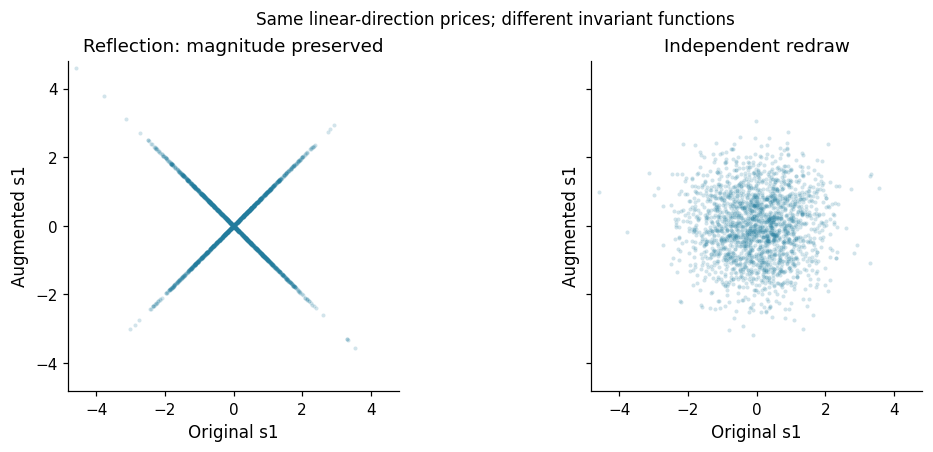

In [15]:
# CHANGED v3 [7]: verify exact copying, then distinguish linear prices from function prices.
def nl_check_sampler_pairing():
    size = 128
    paired = {mode: nl_triplet(size, nl_training_streams(0), NL_WORLD, mode)
              for mode in ['additive', 'flip', 'redraw']}
    reference = paired['additive']
    other_indices = list(range(NC)) + list(range(NC + 1, N))
    for mode, (z, augmented, negative) in paired.items():
        assert torch.equal(z, reference[0]) and torch.equal(negative, reference[2])
        assert torch.equal(augmented[:, other_indices], reference[1][:, other_indices])
        if NL_CONTENT_STD == 0:
            assert torch.equal(z[:, :NC], augmented[:, :NC]), 'Content must be copied exactly.'
    z, augmented, _ = paired['flip']
    assert torch.equal(z[:, NC].abs(), augmented[:, NC].abs())
    print('Sampler checks passed: paired originals/negatives/other changes; exact reflection magnitude.')


def nl_report_augmentations():
    modes = list(dict.fromkeys((c['world'], c['change']) for c in NL_CONDITIONS))
    diagnostics = pd.concat([nl_pair_diagnostics(world, change) for world, change in modes],
                            ignore_index=True)
    nl_write_csv(diagnostics, NL_DIR / 'augmentation_diagnostics.csv')
    print('Sampled prices of coordinates and functions (training-free).')
    print('Variance prices and relative pair MSE are distinct when mean change is nonzero.')
    display(diagnostics[diagnostics.target.isin(['c1', 's1', 'abs_s1', 'sign_s1'])].round(4))
    return diagnostics


def nl_report_linear_prices():
    # Exact population covariances: same in reflection and independent redraw.
    population_sigma = np.eye(N)
    population_delta = np.diag(nl_change_std().numpy().astype(float) ** 2)
    population_delta[NC, NC] = 2.
    z = nl_draw_z(NL_PRICE_SAMPLES, torch.Generator().manual_seed(81001), NL_WORLD)
    original = z.numpy().astype(float)
    sampled_sigma = np.cov(original, rowvar=False)
    rng = np.random.default_rng(81003)
    directions = np.vstack([np.eye(N), rng.normal(size=(12, N))])
    directions /= np.linalg.norm(directions, axis=1, keepdims=True)
    names = COORDS + [f'random_linear_{i+1}' for i in range(12)]
    exact = np.einsum('bi,ij,bj->b', directions, population_delta, directions)
    arrays = dict(population_sigma=population_sigma, population_delta=population_delta,
                  sampled_sigma=sampled_sigma, directions=directions)
    direction_rows, covariance_rows = [], []
    for mode in ['flip', 'redraw']:
        augmented = nl_perturb(z, torch.Generator().manual_seed(81002), NL_WORLD, mode)
        delta = augmented.numpy().astype(float) - original
        estimated_delta = np.cov(delta, rowvar=False)
        arrays[f'sampled_delta_{mode}'] = estimated_delta
        estimated = (np.einsum('bi,ij,bj->b', directions, estimated_delta, directions)
                     / np.einsum('bi,ij,bj->b', directions, sampled_sigma, directions))
        for name, population, sampled in zip(names, exact, estimated):
            direction_rows.append(dict(direction=name, change=mode,
                                       population_price=float(population), sampled_price=float(sampled)))
        covariance_rows.append(dict(change=mode,
                                   max_covariance_error=float(np.abs(estimated_delta-population_delta).max()),
                                   frobenius_covariance_error=float(np.linalg.norm(estimated_delta-population_delta))))
    np.savez_compressed(NL_DIR / 'augmentation_covariances.npz', **arrays)
    directions_frame = pd.DataFrame(direction_rows)
    nl_write_csv(directions_frame, NL_DIR / 'linear_direction_prices.csv')
    nl_write_csv(pd.DataFrame(covariance_rows), NL_DIR / 'covariance_sampling_diagnostics.csv')
    theoretical = pd.DataFrame([
        dict(change='flip', s1_price=2., abs_s1_price=0., sign_s1_price=2.),
        dict(change='redraw', s1_price=2., abs_s1_price=2., sign_s1_price=2.),
    ])
    nl_write_csv(theoretical, NL_DIR / 'population_function_prices.csv')
    print('EXACT design: Sigma_z = I; reflection/redraw share D = diag(content prices, 2, other style prices).')
    print('Thus ALL linear-direction prices agree in population; sampled estimates need not agree exactly.')
    display(theoretical)
    display(pd.DataFrame(covariance_rows).round(4))
    return directions_frame


def nl_plot_augmentation_structure():
    z = nl_draw_z(2000, torch.Generator().manual_seed(70001), NL_WORLD)
    s = z[:, NC].numpy()
    pairs = {mode: nl_perturb(z, torch.Generator().manual_seed(70002), NL_WORLD, mode)[:, NC].numpy()
             for mode in ['flip', 'redraw']}
    limit = 1.05 * max(float(np.abs(s).max()),
                       *(float(np.abs(v).max()) for v in pairs.values()))
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4), sharex=True, sharey=True,
                             layout='constrained')
    for ax, mode, title in zip(axes, ['flip', 'redraw'],
                                ['Reflection: magnitude preserved', 'Independent redraw']):
        ax.scatter(s, pairs[mode], s=7, alpha=.2, linewidths=0, color='#227c9d')
        ax.set(xlabel='Original s1', ylabel='Augmented s1', title=title,
               xlim=(-limit, limit), ylim=(-limit, limit), aspect='equal')
    fig.suptitle('Same linear-direction prices; different invariant functions', fontsize=11)
    fig.savefig(NL_DIR / 'augmentation_structure.png', dpi=200)
    plt.show()
    plt.close(fig)


nl_check_sampler_pairing()
augmentation_diagnostics = nl_report_augmentations()
linear_direction_prices = nl_report_linear_prices()
nl_plot_augmentation_structure()


### Execute or reuse the trajectories

This cell trains and evaluates the planned conditions. A fresh default run performs 720,000 updates across 12 trajectories. Compatible checkpoints and completed evaluations are reused. For a shorter new run, set `NL_BUDGETS = [10000]` and rerun the definitions and plan; later budgets can extend the retained trajectories.


In [16]:
nl = nl_run_all()



Trajectory 1/12: unbounded_d6, seed=0, checkpoints=[10000, 30000, 60000]
unbounded_d6, seed=0: 1/10,000 loss -0.000, alignment 0.000
unbounded_d6, seed=0: 200/10,000 loss -2.756, alignment 1.440
unbounded_d6, seed=0: 400/10,000 loss -3.965, alignment 1.929
unbounded_d6, seed=0: 600/10,000 loss -4.349, alignment 2.109
unbounded_d6, seed=0: 800/10,000 loss -4.810, alignment 2.321
unbounded_d6, seed=0: 1,000/10,000 loss -5.184, alignment 2.383
unbounded_d6, seed=0: 1,200/10,000 loss -5.566, alignment 2.394
unbounded_d6, seed=0: 1,400/10,000 loss -5.707, alignment 2.468
unbounded_d6, seed=0: 1,600/10,000 loss -5.978, alignment 2.525
unbounded_d6, seed=0: 1,800/10,000 loss -6.073, alignment 2.475
unbounded_d6, seed=0: 2,000/10,000 loss -6.284, alignment 2.316
unbounded_d6, seed=0: 2,200/10,000 loss -6.351, alignment 2.550
unbounded_d6, seed=0: 2,400/10,000 loss -6.431, alignment 2.642
unbounded_d6, seed=0: 2,600/10,000 loss -6.517, alignment 2.597
unbounded_d6, seed=0: 2,800/10,000 loss -6

### Results by condition and budget

The saved tables separate the exploratory head comparison from the report's reflection/redraw comparison. Each budget has its own row. Block scores are averaged within each run before calculating means and sample standard deviations across the three seeds. Forward fits and individual-seed reflection/redraw scores are reported separately.


In [17]:
# CHANGED v3 [8]: never pool budgets; expose seed-level magnitude recovery.
NL_GROUPS = ['part', 'condition', 'world', 'head', 'change', 'tau', 'rep_dim', 'updates']
NL_RECOVERY = ['content_mean', 's1', 'abs_s1', 'sign_s1', 'others_mean']
NL_FORWARD = ['h_linear_r2', 'h_kernel_r2', 'h_gap']
NL_FACTOR_METRICS = [f'nonlin_{name}' for name in NL_TARGETS]
NL_EXTRA = ['linear_abs_s1', 's1_probe_gap', 'sat_frac', 'rep_std',
            'rep_std_min', 'rep_std_max', 'rep_cov_min_eigenvalue', 'forward_valid_outputs']


def nl_summary(frame, metrics):
    nl_validate_coverage(frame)
    return frame.groupby(NL_GROUPS, sort=False)[list(dict.fromkeys(metrics))].agg(['mean', 'std', 'count'])


def nl_format(stats, metrics, digits=2):
    output = pd.DataFrame(index=stats.index)
    for metric in metrics:
        def label(row):
            mean, sd, count = row['mean'], row['std'], int(row['count'])
            if count == 0:
                return 'not applicable'
            return (f'{mean:.{digits}f} ± {sd:.{digits}f}' if count > 1
                    else f'{mean:.{digits}f} (n=1)')
        output[metric] = stats[metric].apply(label, axis=1)
    return output


nl_stats = nl_summary(nl, NL_RECOVERY + NL_FORWARD + NL_FACTOR_METRICS + NL_EXTRA)
nl_stats.to_csv(NL_DIR / 'summary_mean_std_count.csv')
formatted_recovery = nl_format(nl_stats, NL_RECOVERY)
head_rows = nl_stats.index.get_level_values('part') == 'heads'
head_table = formatted_recovery[head_rows][['content_mean', 's1', 'others_mean']]
augmentation_table = formatted_recovery[~head_rows]
head_table.to_csv(NL_DIR / 'head_recovery_summary.csv')
augmentation_table.to_csv(NL_DIR / 'augmentation_recovery_summary.csv')
print(f'Output-head comparisons: {NL_CONTENT_LABEL} and style recovery, mean ± sample SD across seeds.')
display(head_table)
print('Reflection/redraw recovery: each budget is a separate row.')
display(augmentation_table)
print('All latent/function targets: held-out kernel-probe R².')
display(nl_format(nl_stats, NL_FACTOR_METRICS))
print('Forward fits for EVERY condition/budget: latents predict representations.')
print('Read high absolute linear R² AND the kernel–linear gap; no claim of exact linearity.')
forward_table = nl_format(nl_stats, NL_FORWARD, digits=3)
forward_table.to_csv(NL_DIR / 'forward_fit_summary.csv')
display(forward_table)
print('Output diagnostics: sigmoid saturation means values <0.05 or >0.95; this does not diagnose its cause.')
print('Nearly constant forward targets (variance ≤1e-12) are excluded from forward R² averages.')
display(nl_format(nl_stats, NL_EXTRA, digits=3))
seed_columns = ['condition', 'head', 'change', 'rep_dim', 'seed', 'updates'] + NL_RECOVERY + NL_FORWARD
seed_recovery = nl[seed_columns].sort_values(['condition', 'seed', 'updates'])
seed_recovery.to_csv(NL_DIR / 'per_seed_recovery.csv', index=False)
print('Individual-seed reflection/redraw trajectories (do not hide seed variation in the mean).')
display(seed_recovery[seed_recovery.change.isin(['flip', 'redraw'])])
print('Completed seeds at EVERY checkpoint; sample SD requires at least two.')
display(nl_stats.xs('count', level=1, axis=1)[['content_mean', 'abs_s1', 'h_linear_r2']])


Output-head comparisons: content and style recovery, mean ± sample SD across seeds.


content_mean  \
part  condition    world    head      change   tau rep_dim updates                
heads unbounded_d6 gaussian unbounded additive 0.1 6       10000    0.97 ± 0.00   
                                                           30000    0.98 ± 0.00   
                                                           60000    0.98 ± 0.01   
      box_d6       gaussian box       additive 0.1 6       10000    0.75 ± 0.06   
                                                           30000    0.82 ± 0.08   
                                                           60000    0.82 ± 0.08   

                                                                              s1  \
part  condition    world    head      change   tau rep_dim updates                 
heads unbounded_d6 gaussian unbounded additive 0.1 6       10000     0.96 ± 0.02   
                                                           30000     0.97 ± 0.01   
                                                           60000     0.97 ± 0.02   
      box_d6       gaussian box       additive 0.1 6       10000     0.47 ± 0.22   
                                                           30000     0.02 ± 0.02   
                                                           60000    -0.00 ± 0.00   

                                                                     others_mean  
part  condition    world    head      change   tau rep_dim updates                
heads unbounded_d6 gaussian unbounded additive 0.1 6       10000     0.00 ± 0.00  
                                                           30000     0.00 ± 0.00  
                                                           60000     0.00 ± 0.01  
      box_d6       gaussian box       additive 0.1 6       10000    -0.00 ± 0.00  
                                                           30000    -0.00 ± 0.00  
                                                           60000    -0.00 ± 0.00

Reflection/redraw recovery: each budget is a separate row.


content_mean  \
part         condition world    head      change tau rep_dim updates                
augmentation flip_d6   gaussian unbounded flip   0.1 6       10000    0.98 ± 0.01   
                                                             30000    0.99 ± 0.00   
                                                             60000    0.99 ± 0.00   
             redraw_d6 gaussian unbounded redraw 0.1 6       10000    0.98 ± 0.01   
                                                             30000    0.99 ± 0.00   
                                                             60000    0.99 ± 0.00   

                                                                                s1  \
part         condition world    head      change tau rep_dim updates                 
augmentation flip_d6   gaussian unbounded flip   0.1 6       10000     0.00 ± 0.01   
                                                             30000     0.01 ± 0.02   
                                                             60000    -0.00 ± 0.00   
             redraw_d6 gaussian unbounded redraw 0.1 6       10000    -0.00 ± 0.00   
                                                             30000    -0.01 ± 0.00   
                                                             60000    -0.01 ± 0.00   

                                                                            abs_s1  \
part         condition world    head      change tau rep_dim updates                 
augmentation flip_d6   gaussian unbounded flip   0.1 6       10000     0.29 ± 0.50   
                                                             30000     0.77 ± 0.16   
                                                             60000     0.94 ± 0.03   
             redraw_d6 gaussian unbounded redraw 0.1 6       10000    -0.00 ± 0.00   
                                                             30000    -0.01 ± 0.00   
                                                             60000    -0.01 ± 0.00   

                                                                           sign_s1  \
part         condition world    head      change tau rep_dim updates                 
augmentation flip_d6   gaussian unbounded flip   0.1 6       10000    -0.00 ± 0.00   
                                                             30000     0.02 ± 0.04   
                                                             60000    -0.00 ± 0.00   
             redraw_d6 gaussian unbounded redraw 0.1 6       10000    -0.00 ± 0.00   
                                                             30000    -0.00 ± 0.00   
                                                             60000    -0.00 ± 0.00   

                                                                       others_mean  
part         condition world    head      change tau rep_dim updates                
augmentation flip_d6   gaussian unbounded flip   0.1 6       10000     0.14 ± 0.12  
                                                             30000     0.01 ± 0.01  
                                                             60000    -0.00 ± 0.00  
             redraw_d6 gaussian unbounded redraw 0.1 6       10000     0.22 ± 0.00  
                                                             30000     0.21 ± 0.00  
                                                             60000     0.21 ± 0.00

All latent/function targets: held-out kernel-probe R².


...

linear_abs_s1  \
part         condition    world    head      change   tau rep_dim updates                   
heads        unbounded_d6 gaussian unbounded additive 0.1 6       10000    -0.001 ± 0.004   
                                                                  30000    -0.003 ± 0.003   
                                                                  60000    -0.003 ± 0.001   
             box_d6       gaussian box       additive 0.1 6       10000     0.002 ± 0.001   
                                                                  30000    -0.003 ± 0.002   
                                                                  60000    -0.004 ± 0.003   
augmentation flip_d6      gaussian unbounded flip     0.1 6       10000     0.285 ± 0.479   
                                                                  30000     0.728 ± 0.172   
                                                                  60000     0.909 ± 0.028   
             redraw_d6    gaussian unbounded redraw   0.1 6       10000    -0.003 ± 0.001   
                                                                  30000    -0.004 ± 0.002   
                                                                  60000    -0.004 ± 0.002   

                                                                             s1_probe_gap  \
part         condition    world    head      change   tau rep_dim updates                   
heads        unbounded_d6 gaussian unbounded additive 0.1 6       10000     0.005 ± 0.009   
                                                                  30000     0.010 ± 0.014   
                                                                  60000     0.023 ± 0.017   
             box_d6       gaussian box       additive 0.1 6       10000     0.033 ± 0.028   
                                                                  30000     0.003 ± 0.001   
                                                                  60000    -0.001 ± 0.002   
augmentation flip_d6      gaussian unbounded flip     0.1 6       10000     0.001 ± 0.005   
                                                                  30000     0.004 ± 0.001   
                                                                  60000    -0.003 ± 0.004   
             redraw_d6    gaussian unbounded redraw   0.1 6       10000    -0.004 ± 0.002   
                                                                  30000    -0.008 ± 0.001   
                                                                  60000    -0.008 ± 0.001   

                                                                                 sat_frac  \
part         condition    world    head      change   tau rep_dim updates                   
heads        unbounded_d6 gaussian unbounded additive 0.1 6       10000    not applicable   
                                                                  30000    not applicable   
                                                                  60000    not applicable   
             box_d6       gaussian box       additive 0.1 6       10000     0.476 ± 0.010   
                                                                  30000     0.589 ± 0.012   
                                                                  60000     0.630 ± 0.016   
augmentation flip_d6      gaussian unbounded flip     0.1 6       10000    not applicable   
                                                                  30000    not applicable   
                                                                  60000    not applicable   
             redraw_d6    gaussian unbounded redraw   0.1 6       10000    not applicable   
                                                                  30000    not applicable   
                                                                  60000    not applicable   

                                                                                 rep_std  \
part         condition    world    head      change   tau rep_dim updates  

Individual-seed reflection/redraw trajectories (do not hide seed variation in the mean).


,condition,head,change,rep_dim,seed,updates,content_mean,s1,abs_s1,sign_s1,others_mean,h_linear_r2,h_kernel_r2,h_gap
18,flip_d6,unbounded,flip,6,0,10000,0.970915,0.007358,0.865579,-0.004056,0.004493,0.954268,0.988492,0.034223
19,flip_d6,unbounded,flip,6,0,30000,0.982272,0.003113,0.947970,-0.002168,0.000648,0.948127,0.989919,0.041792
20,flip_d6,unbounded,flip,6,0,60000,0.989099,-0.000153,0.968986,-0.002627,-0.000399,0.950098,0.991938,0.041841
21,flip_d6,unbounded,flip,6,1,10000,0.983045,-0.004088,0.002358,-0.000270,0.213222,0.979377,0.991404,0.012027
22,flip_d6,unbounded,flip,6,1,30000,0.990614,0.001318,0.745881,-0.000223,0.010244,0.977748,0.994213,0.016465
23,flip_d6,unbounded,flip,6,1,60000,0.990345,-0.000908,0.924072,-0.000435,-0.000374,0.966713,0.993361,0.026648
24,flip_d6,unbounded,flip,6,2,10000,0.980987,-0.003265,0.013101,0.000013,0.207969,0.978579,0.992774,0.014195
25,flip_d6,unbounded,flip,6,2,30000,0.986318,0.040264,0.631011,0.069214,0.011886,0.979455,0.994296,0.014841
26,flip_d6,unbounded,flip,6,2,60000,0.991655,0.000014,0.922534,0.001500,-0.000153,0.973459,0.995160,0.021701
27,redraw_d6,unbounded,redraw,6,0,10000,0.970605,0.001080,-0.001259,-0.001346,0.223330,0.979305,0.990756,0.011451


Completed seeds at EVERY checkpoint; sample SD requires at least two.


content_mean  \
part         condition    world    head      change   tau rep_dim updates                 
heads        unbounded_d6 gaussian unbounded additive 0.1 6       10000               3   
                                                                  30000               3   
                                                                  60000               3   
             box_d6       gaussian box       additive 0.1 6       10000               3   
                                                                  30000               3   
                                                                  60000               3   
augmentation flip_d6      gaussian unbounded flip     0.1 6       10000               3   
                                                                  30000               3   
                                                                  60000               3   
             redraw_d6    gaussian unbounded redraw   0.1 6       10000               3   
                                                                  30000               3   
                                                                  60000               3   

                                                                           abs_s1  \
part         condition    world    head      change   tau rep_dim updates           
heads        unbounded_d6 gaussian unbounded additive 0.1 6       10000         3   
                                                                  30000         3   
                                                                  60000         3   
             box_d6       gaussian box       additive 0.1 6       10000         3   
                                                                  30000         3   
                                                                  60000         3   
augmentation flip_d6      gaussian unbounded flip     0.1 6       10000         3   
                                                                  30000         3   
                                                                  60000         3   
             redraw_d6    gaussian unbounded redraw   0.1 6       10000         3   
                                                                  30000         3   
                                                                  60000         3   

                                                                           h_linear_r2  
part         condition    world    head      change   tau rep_dim updates               
heads        unbounded_d6 gaussian unbounded additive 0.1 6       10000              3  
                                                                  30000              3  
                                                                  60000              3  
             box_d6       gaussian box       additive 0.1 6       10000              3  
                                                                  30000              3  
                                                                  60000              3  
augmentation flip_d6      gaussian unbounded flip     0.1 6       10000              3  
                                                                  30000              3  
                                                                  60000              3  
             redraw_d6    gaussian unbounded redraw   0.1 6       10000              3  
                                                                  30000              3  
                                                                  60000              3

### Recovery figures and training trajectories

Heatmaps show mean held-out kernel-probe $R^2$ for each condition and budget. The colour scale runs from 0 to 1; negative values remain in the annotations. Curves show recovery and forward-fit diagnostics across budgets, including individual-seed magnitude recovery. Shading denotes one sample standard deviation across seeds, not a confidence interval.


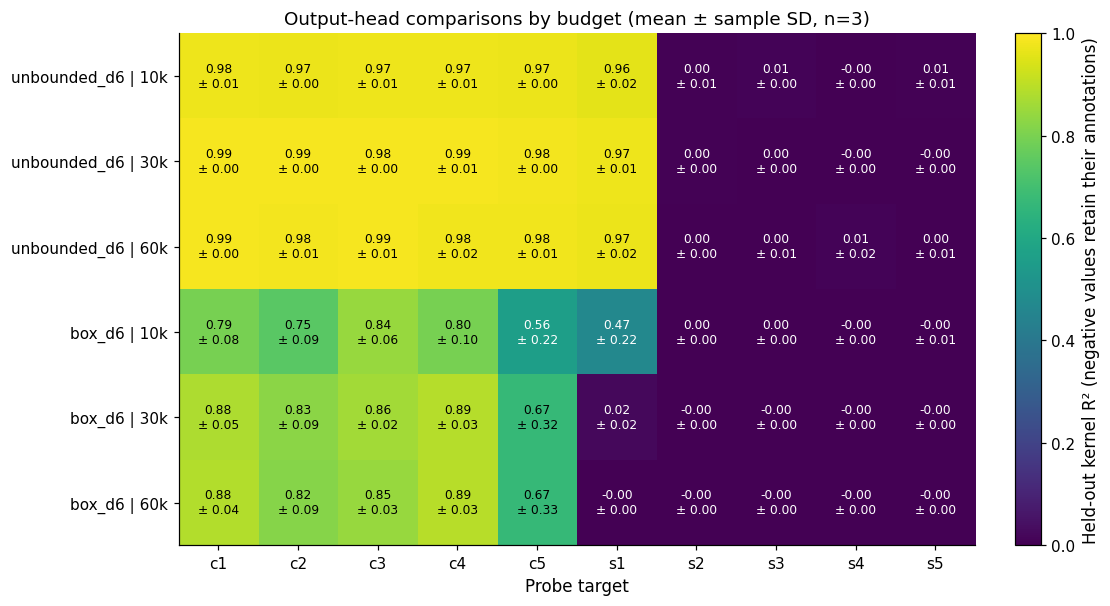

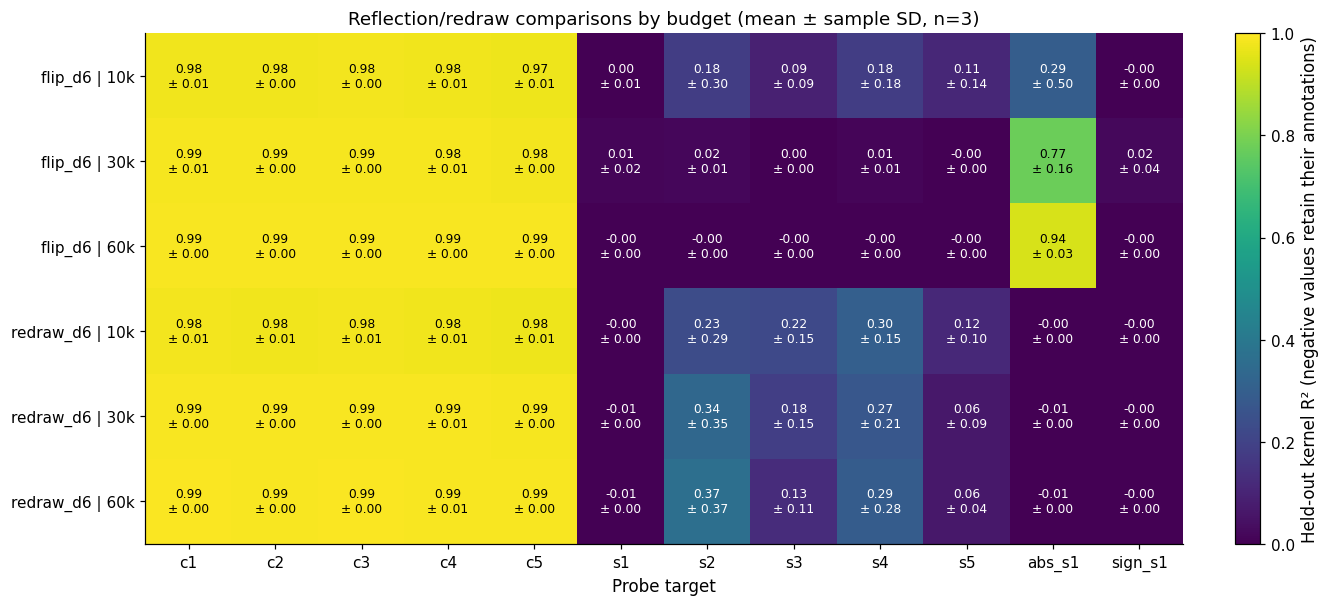

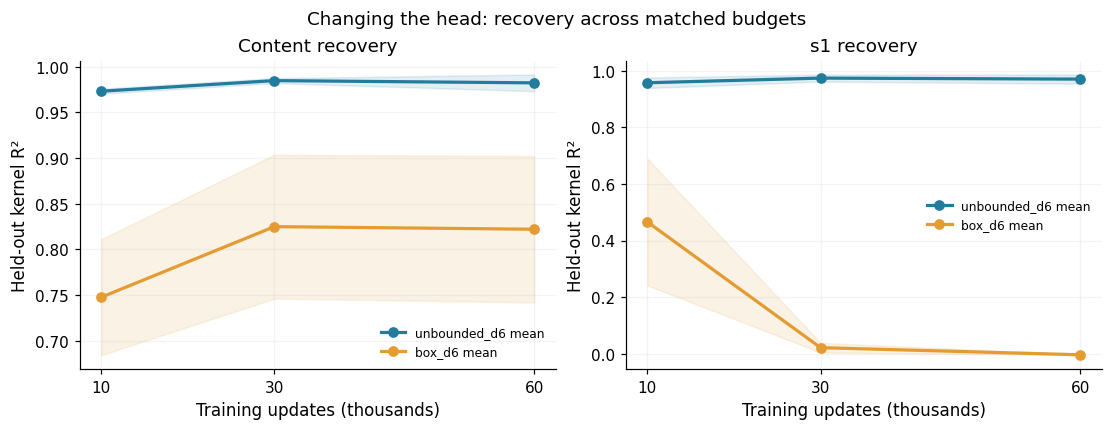

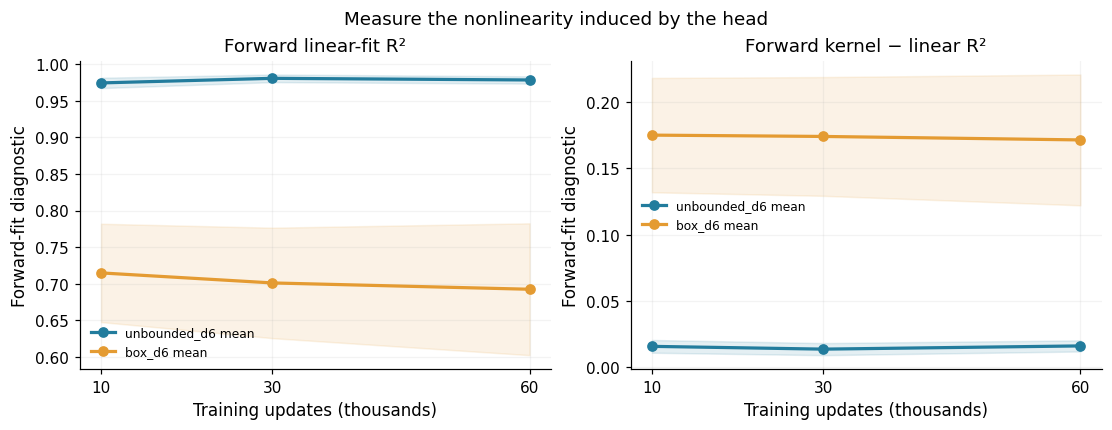

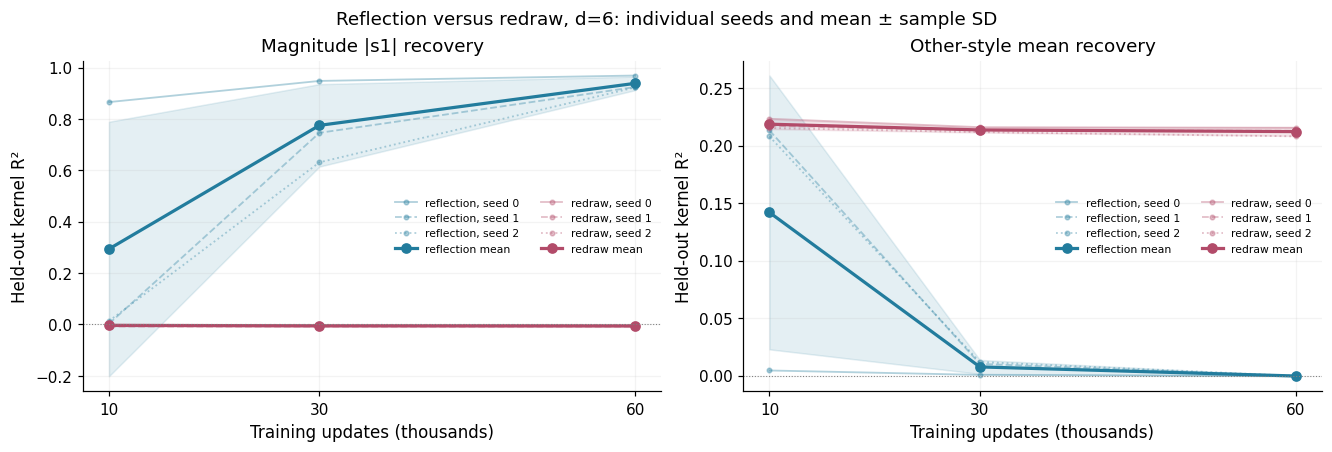

Saved reports and figures: /content/extension_experiment5_gaussian_v3


In [18]:
# CHANGED v3 [9]: budget-aware heatmaps plus paired seed-wise training trajectories.
def nl_recovery_heatmap(frame, part, targets, filename, title):
    subset = frame[frame.part == part]
    if subset.empty:
        return
    order = [(c['label'], b) for c in NL_CONDITIONS if c['part'] == part for b in NL_BUDGETS]
    index = pd.MultiIndex.from_tuples(order, names=['condition', 'updates'])
    columns = [f'nonlin_{target}' for target in targets]
    grouped = subset.groupby(['condition', 'updates'])[columns].agg(['mean', 'std', 'count']).reindex(index)
    means = grouped.xs('mean', level=1, axis=1).to_numpy(float)
    sds = grouped.xs('std', level=1, axis=1).to_numpy(float)
    counts = grouped.xs('count', level=1, axis=1).to_numpy(int)
    fig, ax = plt.subplots(figsize=(max(10, len(targets)), 1.8 + .60 * len(order)),
                            layout='constrained')
    im = ax.imshow(means, aspect='auto', vmin=0, vmax=1, cmap='viridis')
    for i in range(len(order)):
        for j in range(len(targets)):
            label = (f'{means[i,j]:.2f}\n± {sds[i,j]:.2f}' if counts[i,j] > 1
                     else f'{means[i,j]:.2f}')
            ax.text(j, i, label, ha='center', va='center', fontsize=8,
                    color='black' if means[i,j] >= .65 else 'white')
    ax.set_xticks(range(len(targets)), targets)
    ax.set_yticks(range(len(order)), [f'{name} | {budget//1000}k' for name, budget in order])
    n_seeds = subset.seed.nunique()
    note = f'mean ± sample SD, n={n_seeds}' if n_seeds > 1 else 'n=1; no between-seed SD'
    ax.set(title=f'{title} ({note})', xlabel='Probe target')
    fig.colorbar(im, ax=ax, label='Held-out kernel R² (negative values retain their annotations)')
    fig.savefig(NL_DIR / filename, dpi=200)
    plt.show()
    plt.close(fig)


def nl_mean_curve(ax, subset, metric, color, label, show_seeds=False):
    if show_seeds:
        styles = ['-', '--', ':', '-.']
        for index, (seed, values) in enumerate(subset.groupby('seed', sort=True)):
            values = values.sort_values('updates')
            ax.plot(values.updates.to_numpy()/1000, values[metric].to_numpy(),
                    color=color, alpha=.35, linewidth=1.2, linestyle=styles[index % len(styles)],
                    marker='.', label=f'{label}, seed {seed}')
    stats = subset.groupby('updates')[metric].agg(['mean', 'std', 'count']).sort_index()
    x = stats.index.to_numpy(float)/1000
    y, sd = stats['mean'].to_numpy(float), stats['std'].to_numpy(float)
    ax.plot(x, y, color=color, marker='o', linewidth=2.1, label=label + ' mean')
    if (stats['count'] > 1).any():
        ax.fill_between(x, y-sd, y+sd, color=color, alpha=.12)
    ax.set_xticks([b/1000 for b in NL_BUDGETS])
    ax.set_xlabel('Training updates (thousands)')
    ax.grid(alpha=.15)


def nl_plot_head_trajectories(frame):
    subset = frame[frame.part == 'heads']
    if subset.empty:
        return
    colors = ['#227c9d', '#e49b32', '#7b4ab5', '#35a66e']
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
    fig_forward, forward_axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
    for index, condition in enumerate(c for c in NL_CONDITIONS if c['part'] == 'heads'):
        rows = subset[subset.condition == condition['label']]
        color = colors[index % len(colors)]
        for ax, metric in zip(axes, ['content_mean', 's1']):
            nl_mean_curve(ax, rows, metric, color, condition['label'])
        for ax, metric in zip(forward_axes, ['h_linear_r2', 'h_gap']):
            nl_mean_curve(ax, rows, metric, color, condition['label'])
    for ax, title in zip(axes, [NL_CONTENT_LABEL.capitalize() + ' recovery', 's1 recovery']):
        ax.set(title=title, ylabel='Held-out kernel R²')
        ax.legend(frameon=False, fontsize=8)
    for ax, title in zip(forward_axes, ['Forward linear-fit R²', 'Forward kernel − linear R²']):
        ax.set(title=title, ylabel='Forward-fit diagnostic')
        ax.legend(frameon=False, fontsize=8)
    fig.suptitle('Changing the head: recovery across matched budgets')
    fig_forward.suptitle('Measure the nonlinearity induced by the head')
    fig.savefig(NL_DIR / 'head_training_trajectories.png', dpi=200)
    fig_forward.savefig(NL_DIR / 'head_forward_fits.png', dpi=200)
    plt.show()
    plt.close(fig)
    plt.close(fig_forward)


def nl_plot_augmentation_trajectories(frame):
    subset = frame[frame.part == 'augmentation']
    for rep_dim in subset.rep_dim.unique():
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
        for mode, color, name in [('flip', '#227c9d', 'reflection'), ('redraw', '#b24b69', 'redraw')]:
            rows = subset[(subset.change == mode) & (subset.rep_dim == rep_dim)]
            if rows.empty:
                continue
            for ax, metric in zip(axes, ['abs_s1', 'others_mean']):
                nl_mean_curve(ax, rows, metric, color, name, show_seeds=True)
        for ax, title in zip(axes, ['Magnitude |s1| recovery', 'Other-style mean recovery']):
            ax.axhline(0, color='#808080', linewidth=.7, linestyle=':')
            ax.set(title=title, ylabel='Held-out kernel R²')
            ax.legend(frameon=False, fontsize=7, ncol=2)
        # No y-axis clipping: weak/negative individual-seed scores must remain visible.
        fig.suptitle(f'Reflection versus redraw, d={rep_dim}: individual seeds and mean ± sample SD')
        fig.savefig(NL_DIR / f'reflection_redraw_trajectories_d{rep_dim}.png', dpi=200)
        plt.show()
        plt.close(fig)


nl_recovery_heatmap(nl, 'heads', COORDS, 'head_recovery.png', 'Output-head comparisons by budget')
nl_recovery_heatmap(nl, 'augmentation', NL_TARGETS,
                    'reflection_redraw_recovery.png', 'Reflection/redraw comparisons by budget')
nl_plot_head_trajectories(nl)
nl_plot_augmentation_trajectories(nl)
nl_atomic_json(NL_DIR / 'run_status.json', dict(status='complete', plan_id=NL_PLAN_ID,
                                            trajectories=len(NL_PLAN), completed_evaluations=len(nl)))
print('Saved reports and figures:', NL_DIR.resolve())


### Interpretation and scope

Under reflection, mean kernel-probe recovery of $|s_1|$ rises from $0.29\pm0.50$ at 10,000 updates to $0.77\pm0.16$ at 30,000 and $0.94\pm0.03$ at 60,000; every seed exceeds $0.92$ at the final checkpoint. Under redraw, magnitude recovery remains near zero. Content recovery is high in both conditions, while the signed coordinate and its sign have near-zero probe scores. These results support retention of the nonlinear invariant available under reflection, with substantial variation in how quickly it is learned.

The exploratory sigmoid-head comparison changes the representation geometry and distances in InfoNCE as well as the composite map. Its recovery differences therefore do not isolate nonlinearity as a cause. An identity output head also leaves the preceding encoder nonlinear.

Probe scores describe recoverability by the fitted probes; they do not establish exact block-identifiability, complete absence of information, or global optimality. The reflection/redraw runs use six outputs and finite-negative InfoNCE, so they are not direct tests of the original paper's population alignment–entropy theorem.

Execution writes recovery and forward-fit tables, sampler diagnostics, figures, held-out arrays and checkpoints to `NL_DIR`. The saved notebook contains the displayed outputs; these external files must be retained separately for reuse.

### References

- von Kügelgen et al. (2021). [*Self-Supervised Learning with Data Augmentations Provably Isolates Content from Style*](https://arxiv.org/abs/2106.04619). NeurIPS. Source of the latent model, augmentation framework and simulation design.
- [Released simulation implementation](https://github.com/ysharma1126/ssl_identifiability/tree/ee46a35acf68461172b3eaeeb1d6fbc779fce661), especially `main_mlp.py`, `spaces.py` and `losses.py`. The present notebook adapts these components and adds the comparisons documented above.
